In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcdefaults()  
plt.rcParams['text.usetex'] = True
import astropy.units as u
from astropy.coordinates import SkyCoord, Galactocentric
from matplotlib.lines import Line2D

In [3]:
cs = pd.read_csv('../data/true_sources_final_kinematics.csv',dtype={'source_id': str})

In [4]:
mask_disk = cs['V_tot'] < 180
mask_halo = cs['V_tot'] > 180

In [5]:
cs['age'] = cs['age']/1000

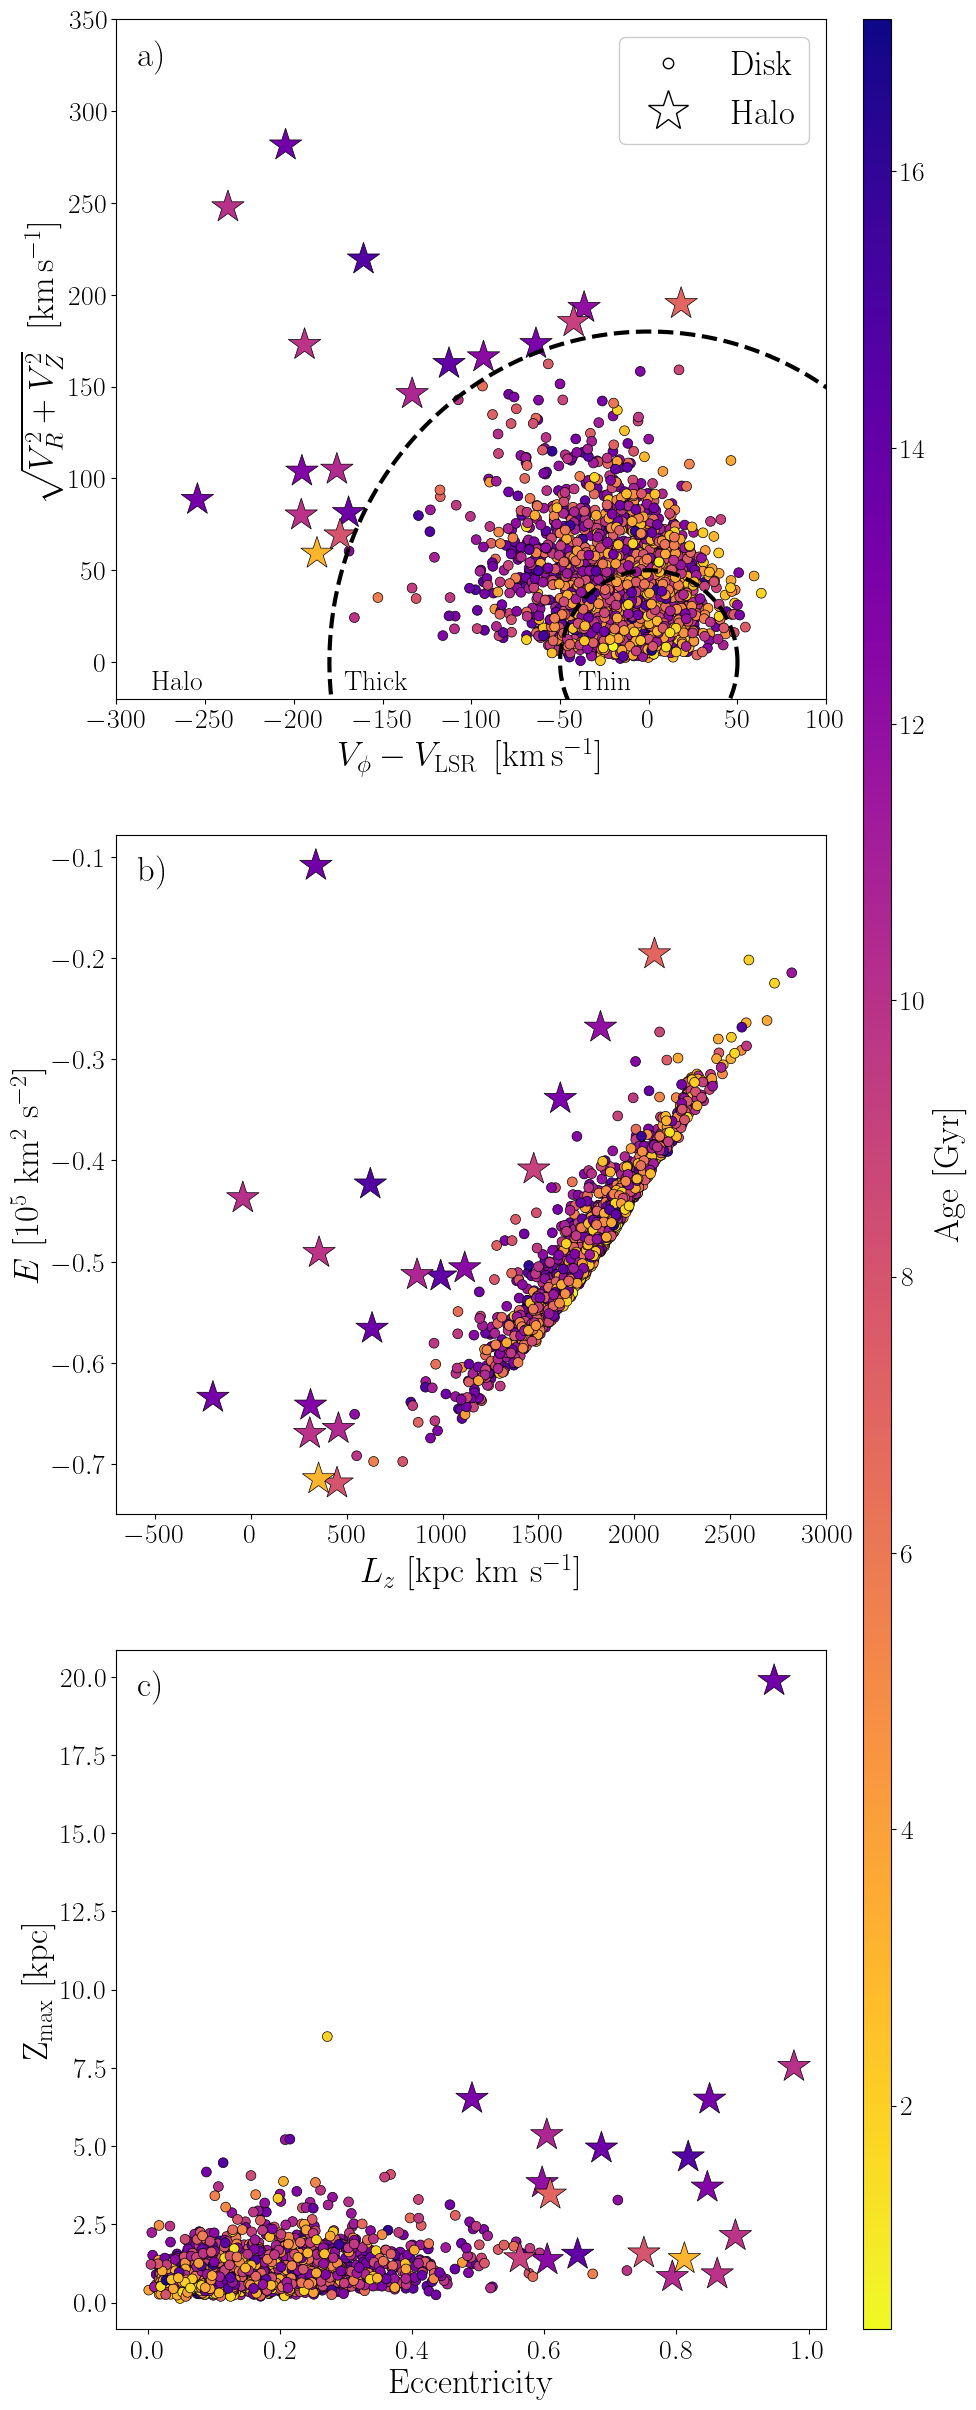

In [ ]:
fig, axes = plt.subplot_mosaic(
    [['toomre', 'cbar'],
     ['elz',    'cbar'],
     ['zmax',   'cbar']],
    figsize=(10, 30),
    width_ratios=[1, 0.04],
    gridspec_kw={'hspace': 0.2, 'wspace': 0.1}
)
ax1, ax2, ax3, cax = axes['toomre'], axes['elz'], axes['zmax'], axes['cbar']
theta = np.linspace(0, 2*np.pi, 500)

# Colourmap setup
cmap = 'plasma_r'
norm = plt.Normalize(vmin=cs['age'].min(), vmax=cs['age'].max())

# ============================================================================
# TOP: Toomre diagram
# ============================================================================
ax1.scatter(
    cs.loc[mask_disk, 'V_phi_rel'],
    cs.loc[mask_disk, 'V_perp'],
    edgecolor='black', c=cs.loc[mask_disk, 'age'], cmap=cmap, norm=norm,
    s=50, lw=0.5, marker='o', rasterized=True,
    label=r'$v_\mathrm{tot} \leq 180\ \mathrm{km\,s^{-1}}$'
)
ax1.scatter(
    cs.loc[mask_halo, 'V_phi_rel'],
    cs.loc[mask_halo, 'V_perp'],
    edgecolor='black', c=cs.loc[mask_halo, 'age'], cmap=cmap, norm=norm,
    s=600, lw=0.5, marker='*', rasterized=True,
    label=r'$v_\mathrm{tot} > 180\ \mathrm{km\,s^{-1}}$'
)

for radius in [50, 180]:
    ax1.plot(radius * np.cos(theta), radius * np.sin(theta), 'k--', lw=3)

ax1.set_xlabel(r'$V_\phi - V_{\rm LSR}\ \, [{\rm km\,s^{-1}}]$', fontsize=25)
ax1.set_ylabel(r'$\sqrt{V_R^2 + V_Z^2}\ \, \,[{\rm km\,s^{-1}}]$', fontsize=25)
ax1.set_xlim(-300, 100)
ax1.set_ylim(-20, 350)
ax1.text(-40,  -15, r'$\mathrm{Thin}$',  fontsize=20, c='black')
ax1.text(-172, -15, r'$\mathrm{Thick}$', fontsize=20, c='black')
ax1.text(-280, -15, r'$\mathrm{Halo}$',  fontsize=20, c='black')
ax1.tick_params(axis='both', which='major', labelsize=20)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=5, label=r'$\mathrm{Disk}$'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=20, label=r'$\mathrm{Halo}$'),
]
ax1.legend(handles=legend_handles, fontsize=25, markerscale=1.5, facecolor='white', framealpha=1,loc='upper right')

# ============================================================================
# MIDDLE: E–Lz diagram
# ============================================================================
ax2.scatter(
    (cs.loc[~mask_halo, 'Lz']),
    cs.loc[~mask_halo, 'Energy']/100000,
    s=50, c=cs.loc[~mask_halo, 'age'], cmap=cmap, norm=norm,
    marker='o', label=r'$\mathrm{Disk}$', edgecolor='black', lw=0.5, rasterized=True
)
ax2.scatter(
    (cs.loc[mask_halo, 'Lz']),
    cs.loc[mask_halo, 'Energy']/100000,
    s=600, edgecolor='black', lw=0.5, c=cs.loc[mask_halo, 'age'], cmap=cmap, norm=norm,
    marker='*', label=r'$\mathrm{Halo}$', rasterized=True
)

ax2.set_xlabel(r'$L_z\ \mathrm{[kpc\ km\ s^{-1}]}$', fontsize=25)
ax2.set_ylabel(r'$E\ \mathrm{[10^5 \ km^2\ s^{-2}]}$', fontsize=25)
ax2.tick_params(axis='both', which='major', labelsize=20)
ax2.set_xlim(-700, 3000)


# ============================================================================
# BOTTOM: Eccentricity vs Z_max
# ============================================================================
ax3.scatter(
    cs.loc[mask_disk, 'eccentricity'],
    cs.loc[mask_disk, 'Z_max'],
    edgecolor='black', c=cs.loc[mask_disk, 'age'], cmap=cmap, norm=norm,
    s=50, lw=0.5, marker='o', rasterized=True,
    label=r'$v_\mathrm{tot} \leq 180\ \mathrm{km\,s^{-1}}$'
)
ax3.scatter(
    cs.loc[mask_halo, 'eccentricity'],
    cs.loc[mask_halo, 'Z_max'],
    edgecolor='black', c=cs.loc[mask_halo, 'age'], cmap=cmap, norm=norm,
    s=600, lw=0.5, marker='*', rasterized=True,
    label=r'$v_\mathrm{tot} > 180\ \mathrm{km\,s^{-1}}$'
)
ax3.set_xlabel(r'$\mathrm{Eccentricity}$', fontsize=25)
ax3.set_ylabel(r'$\mathrm{Z_{max} \,\,[kpc]}$', fontsize=25)
ax3.tick_params(axis='both', which='major', labelsize=20)

# ============================================================================
# Panel labels
# ============================================================================
for ax, label in zip([ax1, ax2, ax3], ['$\mathrm{a)}$', '$\mathrm{b)}$', '$\mathrm{c)}$']):
    ax.text(0.03, 0.97, label, transform=ax.transAxes,
            fontsize=25, va='top', ha='left', color='black', fontweight='extra bold')

# ============================================================================
# Shared colourbar spanning all three rows
# ============================================================================
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_label(r'$\mathrm{Age\ [Gyr]}$', fontsize=25)
cbar.ax.tick_params(labelsize=20)

# ============================================================================
# Save
# ============================================================================
plt.savefig('../figures/toomre_elz_zmax_combined_age.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [7]:
cs[mask_halo].to_csv('../data/kinematic_halo.csv',index=False)